# 02 — Build the fight-level dataset

Turns the raw tables into one clean, chronological row per fight, with the
fighter-ordering leakage removed (see `data/randomize.py`).

**Where the raw tables come from.** Since Day 9: the Kaggle dataset
`scarekrow/ufc-data`, every UFC fight on ufcstats.com from 1994 to the latest
card. `data/source.refresh()` downloads it (newest or a pinned version),
converts it into the three tables this pipeline reads, refuses to silently
rewrite past fights, and records the exact version in
`data/raw/source/SOURCE.json`.

**Every fight is kept, including draws and no-contests.** They can't be
modelling rows — there is no winner to predict — so `fighter_a_won` is
`<NA>` for them and `outcome` says which kind they are. But they are real
fights: the strikes landed, the cage time elapsed, the fighter wasn't
resting. `modeling.split.drop_undecided` removes them at the point where
modelling rows are chosen, after the features have been built.

All the actual transform logic lives in `src/ufc_predictor/data/` — this
notebook just calls it and checks the result, so the logic can't drift
between "what the notebook does" and "what the pipeline does".

In [1]:
import json

from ufc_predictor.config import RAW_DIR
from ufc_predictor.data.build import build_fight_dataset
from ufc_predictor.data.io import save_processed

# which version of the source these tables were converted from
source = json.loads((RAW_DIR / "source" / "SOURCE.json").read_text())
print(f"{source['dataset']} version {source['version']} (downloaded {source['downloaded_on']}): "
      f"{source['fights']:,} fights, {source['first_event']} to {source['last_event']}")

fights = build_fight_dataset()

scarekrow/ufc-data version 18 (downloaded 2026-10-05): 8,911 fights, 1994-03-11 to 2026-09-26


## Sanity checks

The things that would silently break the project if they were wrong.

In [2]:
# every fight in the source is kept
assert len(fights) == source["fights"]
assert fights["event_date"].is_monotonic_increasing

print(fights["outcome"].value_counts().to_string())

# the label is nullable: a plain bool column would quietly call every
# undecided fight a fighter_b win
assert fights["fighter_a_won"].dtype == "boolean"
decided = fights[fights["fighter_a_won"].notna()]

overall_rate = decided["fighter_a_won"].mean()
print(f"\nfighter_a win rate, overall: {overall_rate:.3f}")
assert 0.45 < overall_rate < 0.55

outcome
fighter_b     4432
fighter_a     4323
no_contest      92
draw            64

fighter_a win rate, overall: 0.494


In [3]:
# the bug this notebook exists to fix: the source lists the winner first in
# every decided fight (the previous source did the same before 2010). after
# the coin flip, every era should look like a coin flip too, not a flat 100%.
for name, era in [("pre-2010", decided["event_date"].dt.year < 2010),
                  ("2010 onwards", decided["event_date"].dt.year >= 2010)]:
    rate = decided.loc[era, "fighter_a_won"].mean()
    print(f"fighter_a win rate, {name} ({era.sum():,} fights): {rate:.3f}")
    assert 0.40 < rate < 0.60

fighter_a win rate, pre-2010 (1,250 fights): 0.493
fighter_a win rate, 2010 onwards (7,505 fights): 0.494


<Axes: title={'center': 'fighter_a win rate by year (should hover near 0.5 throughout)'}, xlabel='event_date'>

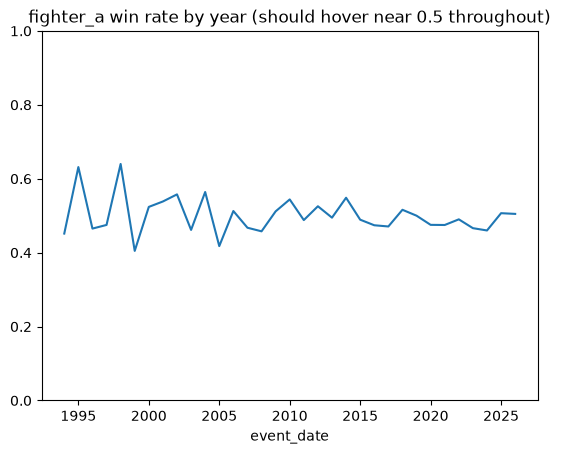

In [4]:
decided.groupby(decided["event_date"].dt.year)["fighter_a_won"].mean().plot(
    title="fighter_a win rate by year (should hover near 0.5 throughout)",
    ylim=(0, 1),
)

## Save

In [5]:
save_processed(fights, "fights")
fights.head()

,weight_class,fights_url,event_url,event_date,fighter_a_age_during,fighter_b_age_during,fighter_a_body_strike_atts,fighter_b_body_strike_atts,fighter_a_body_strikes,fighter_b_body_strikes,...,fighter_a_takedowns,fighter_b_takedowns,fighter_a_tot_strike_atts,fighter_b_tot_strike_atts,fighter_a_tot_strikes,fighter_b_tot_strikes,fighter_a_total_fight_time,fighter_b_total_fight_time,fighter_a_won,outcome
0,Catch Weight Bout,http://www.ufcstats.com/fight-details/4acab678...,http://www.ufcstats.com/event-details/a6a9ab5a...,1994-03-11,18.0,NaN,0.0,0.0,0.0,0.0,...,0,1,5,2,1,2,20,20,False,fighter_b
1,UFC Catch Weight Title Bout,http://www.ufcstats.com/fight-details/00835554...,http://www.ufcstats.com/event-details/a6a9ab5a...,1994-03-11,27.0,30.0,0.0,2.0,0.0,1.0,...,1,0,11,3,11,2,77,77,True,fighter_a
2,Catch Weight Bout,http://www.ufcstats.com/fight-details/aa161c71...,http://www.ufcstats.com/event-details/a6a9ab5a...,1994-03-11,24.0,27.0,0.0,0.0,0.0,0.0,...,0,1,0,0,0,0,91,91,False,fighter_b
3,Catch Weight Bout,http://www.ufcstats.com/fight-details/8fbdde20...,http://www.ufcstats.com/event-details/a6a9ab5a...,1994-03-11,NaN,30.0,0.0,2.0,0.0,2.0,...,0,0,9,12,4,5,67,67,False,fighter_b
4,Catch Weight Bout,http://www.ufcstats.com/fight-details/5655639b...,http://www.ufcstats.com/event-details/a6a9ab5a...,1994-03-11,24.0,27.0,0.0,0.0,0.0,0.0,...,1,0,0,0,0,0,67,67,False,fighter_b
